# Set 11: EDA + Apriori

**Q1 → Exp 1A / 2** · **Q2 → Exp 9** (Apriori)

Datasets: Q1 `Diabetes.csv`. Q2 asks for `Supermarket.csv`, which we don't have, so this uses **`Shop1.csv`** (your Exp9 shopping baskets). The thresholds are the paper's: **support 10%, confidence 70%**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")      # hides library warnings so the output stays clean

---
## Question 1

### Q1.1 Read the data

In [2]:
df = pd.read_csv("data/Diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### Q1.2 Display the columns with null values

In [3]:
nulls = df.isnull().sum()
print(nulls)
print("\nColumns with null values:", list(nulls[nulls > 0].index))

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Columns with null values: []


### Q1.3 5-number summary, correlated with a box plot

min     0.0
25%    27.3
50%    32.0
75%    36.6
max    67.1
Name: BMI, dtype: float64


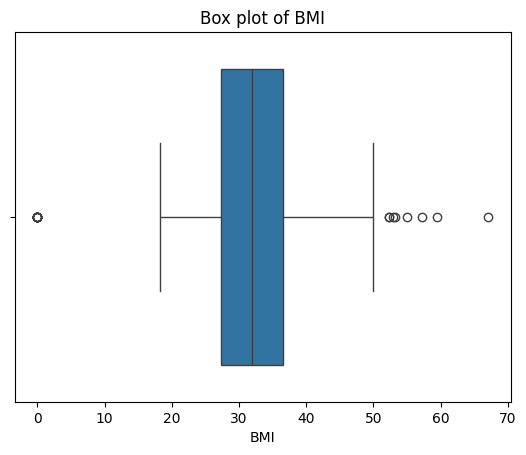

In [4]:
col = "BMI"
print(df[col].describe()[["min", "25%", "50%", "75%", "max"]])     # the 5-number summary

sns.boxplot(x=df[col])
plt.title("Box plot of " + col)
plt.show()

**Correlate with the box plot:** left edge of the box = 25%, middle line = 50% (median), right edge = 75%, whiskers reach towards min and max, and dots beyond the whiskers are outliers.

### Q1.4 Counts of a categorical variable (count plot)

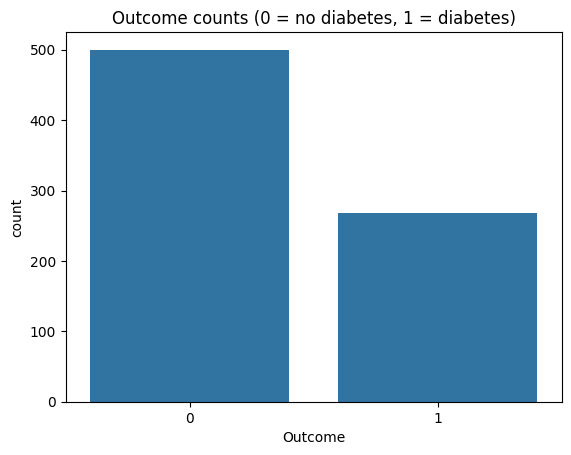

Outcome
0    500
1    268
Name: count, dtype: int64


In [5]:
sns.countplot(x="Outcome", data=df)
plt.title("Outcome counts (0 = no diabetes, 1 = diabetes)")
plt.show()
print(df["Outcome"].value_counts())

### Q1.5 Univariate feature selection (SelectKBest, SelectPercentile)

In [6]:
from sklearn.feature_selection import SelectKBest, SelectPercentile, f_classif

X = df.drop(columns="Outcome")
y = df["Outcome"]
kbest = SelectKBest(f_classif, k=4).fit(X, y)
print("SelectKBest (k=4):", list(kbest.get_feature_names_out()))
perc = SelectPercentile(f_classif, percentile=50).fit(X, y)
print("SelectPercentile (50%):", list(perc.get_feature_names_out()))
print(pd.Series(kbest.scores_, index=X.columns).sort_values(ascending=False).round(1))

SelectKBest (k=4): ['Pregnancies', 'Glucose', 'BMI', 'Age']
SelectPercentile (50%): ['Pregnancies', 'Glucose', 'BMI', 'Age']
Glucose                     213.2
BMI                          71.8
Age                          46.1
Pregnancies                  39.7
DiabetesPedigreeFunction     23.9
Insulin                      13.3
SkinThickness                 4.3
BloodPressure                 3.3
dtype: float64


---
## Question 2

### Q2.1 Read the data

In [7]:
from mlxtend.preprocessing import TransactionEncoder

shop = pd.read_csv("data/Shop1.csv", header=None)
transactions = [[item.strip() for item in row.dropna()] for _, row in shop.iterrows()]   # one list per basket
te = TransactionEncoder()
basket = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)   # True/False table
print(len(transactions), "transactions,", basket.shape[1], "items")
basket.head()

250 transactions, 22 items


,Apples,Bananas,Beer,Biscuits,Bread,Butter,Cheese,Chips,Coffee,Cola,...,Eggs,Jam,Milk,Oil,Onions,Rice,Sugar,Tea,Tomatoes,Yogurt
0,False,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,True,False,False,False,False,False,...,True,False,True,False,False,False,False,False,False,False
2,False,True,False,False,True,True,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,True,False,True,...,False,False,False,False,False,False,True,True,False,False
4,True,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,False,True,False,False,False


### Q2.2 Display the candidate set (C) and frequent set (L) for every iteration
This is Apriori written out step by step: count every candidate, keep those with support ≥ 10%, then join the survivors to make the next, bigger candidates.

In [8]:
MIN_SUPPORT = 0.10
candidates = [frozenset([item]) for item in basket.columns]
k = 1
while candidates:
    support = {c: basket[list(c)].all(axis=1).mean() for c in candidates}   # % of baskets holding ALL items of c
    frequent = [c for c in candidates if support[c] >= MIN_SUPPORT]
    print(f"Iteration {k}:  C{k} = {len(candidates)} candidates,  L{k} = {len(frequent)} frequent")
    for c in frequent:
        print("   ", sorted(c), round(support[c], 3))
    k += 1
    candidates = list({a | b for a in frequent for b in frequent if len(a | b) == k})   # join step

Iteration 1:  C1 = 22 candidates,  L1 = 16 frequent
    ['Apples'] 0.108
    ['Biscuits'] 0.168
    ['Bread'] 0.448
    ['Butter'] 0.368
    ['Chips'] 0.236
    ['Coffee'] 0.18
    ['Cola'] 0.216
    ['Dal'] 0.224
    ['Eggs'] 0.212
    ['Jam'] 0.18
    ['Milk'] 0.3
    ['Oil'] 0.168
    ['Rice'] 0.3
    ['Sugar'] 0.308
    ['Tea'] 0.252
    ['Tomatoes'] 0.12
Iteration 2:  C2 = 120 candidates,  L2 = 19 frequent
    ['Chips', 'Cola'] 0.164
    ['Sugar', 'Tea'] 0.184
    ['Dal', 'Rice'] 0.224
    ['Bread', 'Eggs'] 0.108
    ['Bread', 'Jam'] 0.124
    ['Butter', 'Milk'] 0.104
    ['Eggs', 'Milk'] 0.136
    ['Butter', 'Rice'] 0.104
    ['Biscuits', 'Tea'] 0.1
    ['Bread', 'Dal'] 0.104
    ['Bread', 'Butter'] 0.312
    ['Bread', 'Tea'] 0.104
    ['Bread', 'Milk'] 0.2
    ['Butter', 'Jam'] 0.108
    ['Dal', 'Oil'] 0.104
    ['Bread', 'Sugar'] 0.12
    ['Coffee', 'Sugar'] 0.104
    ['Bread', 'Rice'] 0.14
    ['Oil', 'Rice'] 0.108
Iteration 3:  C3 = 41 candidates,  L3 = 4 frequent
    ['Dal',

### Q2.3 Display the association rules (confidence ≥ 70%)

In [9]:
from mlxtend.frequent_patterns import apriori, association_rules

itemsets = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True)
rules = association_rules(itemsets, metric="confidence", min_threshold=0.70)
rules[["antecedents", "consequents", "support", "confidence", "lift"]].round(3)

,antecedents,consequents,support,confidence,lift
0,(Butter),(Bread),0.312,0.848,1.892
1,(Cola),(Chips),0.164,0.759,3.217
2,(Dal),(Rice),0.224,1.000,3.333
3,(Rice),(Dal),0.224,0.747,3.333
4,(Tea),(Sugar),0.184,0.730,2.371
5,"(Jam, Bread)",(Butter),0.108,0.871,2.367
6,"(Jam, Butter)",(Bread),0.108,1.000,2.232
7,"(Milk, Butter)",(Bread),0.100,0.962,2.146
8,"(Dal, Bread)",(Rice),0.104,1.000,3.333
9,"(Rice, Bread)",(Dal),0.104,0.743,3.316


### Q2.4 Rules with the highest confidence

In [10]:
rules.sort_values("confidence", ascending=False)[["antecedents", "consequents", "confidence", "lift"]].head(5).round(3)

,antecedents,consequents,confidence,lift
2,(Dal),(Rice),1.000,3.333
6,"(Jam, Butter)",(Bread),1.000,2.232
8,"(Dal, Bread)",(Rice),1.000,3.333
10,"(Dal, Oil)",(Rice),1.000,3.333
11,"(Rice, Oil)",(Dal),0.963,4.299


Support = how often the items appear together. Confidence = when A is bought, how often B is also bought. Lift > 1 = A really boosts B.